In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("loans_granting_model_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

C:\Users\Umesh eshwar reddy\AppData\Local\Temp\ipykernel_30788\3863866248.py:1: DtypeWarning: Columns (14: desc) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("loans_granting_model_dataset.csv")


Dataset loaded successfully!
Shape: (1347681, 15)


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1347681 entries, 0 to 1347680
Data columns (total 15 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   id                1347681 non-null  int64  
 1   issue_d           1347681 non-null  str    
 2   revenue           1347681 non-null  float64
 3   dti_n             1347681 non-null  float64
 4   loan_amnt         1347681 non-null  int64  
 5   fico_n            1347681 non-null  float64
 6   experience_c      1347681 non-null  int64  
 7   emp_length        1347681 non-null  str    
 8   purpose           1347681 non-null  str    
 9   home_ownership_n  1347681 non-null  str    
 10  addr_state        1347681 non-null  str    
 11  zip_code          1347680 non-null  str    
 12  Default           1347681 non-null  int64  
 13  title             1331024 non-null  str    
 14  desc              119099 non-null   str    
dtypes: float64(3), int64(4), str(8)
memory usage: 254.3 MB


In [5]:
df.isnull().sum()

id                        0
issue_d                   0
revenue                   0
dti_n                     0
loan_amnt                 0
fico_n                    0
experience_c              0
emp_length                0
purpose                   0
home_ownership_n          0
addr_state                0
zip_code                  1
Default                   0
title                 16657
desc                1228582
dtype: int64

In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
df.describe()

,id,revenue,dti_n,loan_amnt,fico_n,experience_c,Default
count,1.347681e+06,1.347681e+06,1.347681e+06,1.347681e+06,1.347681e+06,1.347681e+06,1.347681e+06
mean,5.621359e+07,7.736968e+04,1.829909e+01,1.440823e+04,6.981589e+02,9.999814e-01,1.997869e-01
std,3.839501e+07,7.036299e+04,1.115214e+01,8.715347e+03,3.184872e+01,4.306977e-03,3.998402e-01
min,5.473400e+04,1.896000e+03,0.000000e+00,5.000000e+02,6.120000e+02,0.000000e+00,0.000000e+00
25%,1.970651e+07,4.660000e+04,1.182000e+01,7.975000e+03,6.720000e+02,1.000000e+00,0.000000e+00
50%,5.766422e+07,6.500000e+04,1.763000e+01,1.200000e+04,6.920000e+02,1.000000e+00,0.000000e+00
75%,8.449505e+07,9.200000e+04,2.407000e+01,2.000000e+04,7.120000e+02,1.000000e+00,0.000000e+00
max,1.456364e+08,1.099920e+07,9.990000e+02,4.000000e+04,8.475000e+02,1.000000e+00,1.000000e+00


### Data cleaning 

In [8]:
print("Duplicate rows:", df.duplicated().sum())

print("Unique loan IDs:", df["id"].nunique())

print("Duplicate loan IDs:", df["id"].duplicated().sum())

Duplicate rows: 0
Unique loan IDs: 1347681
Duplicate loan IDs: 0


In [9]:
categorical_columns = [
    "emp_length",
    "purpose",
    "home_ownership_n",
    "addr_state"
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(20))


--- emp_length ---
emp_length
10+ years    442667
2 years      122091
< 1 year     108517
3 years      107862
1 year        88841
5 years       84326
4 years       80761
NI            78188
6 years       62877
8 years       60808
7 years       59724
9 years       51019
Name: count, dtype: int64

--- purpose ---
purpose
debt_consolidation    781206
credit_card           295551
home_improvement       87684
other                  78263
major_purchase         29543
medical                15606
small_business         15575
car                    14647
moving                  9520
vacation                9083
house                   7294
wedding                 2350
renewable_energy         936
educational              423
Name: count, dtype: int64

--- home_ownership_n ---
home_ownership_n
MORTGAGE    666594
RENT        535585
OWN         144985
OTHER          517
Name: count, dtype: int64

--- addr_state ---
addr_state
CA    196805
TX    110307
NY    110075
FL     95815
IL     51858
NJ   

In [10]:
numerical_columns = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n"
]

for col in numerical_columns:
    print(f"\n--- {col} ---")
    print(df[col].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ))


--- revenue ---
count    1.347681e+06
mean     7.736968e+04
std      7.036299e+04
min      1.896000e+03
1%       1.900000e+04
5%       2.832900e+04
25%      4.660000e+04
50%      6.500000e+04
75%      9.200000e+04
95%      1.600000e+05
99%      2.600000e+05
max      1.099920e+07
Name: revenue, dtype: float64

--- dti_n ---
count    1.347681e+06
mean     1.829909e+01
std      1.115214e+01
min      0.000000e+00
1%       1.800000e+00
5%       5.000000e+00
25%      1.182000e+01
50%      1.763000e+01
75%      2.407000e+01
95%      3.299000e+01
99%      3.848000e+01
max      9.990000e+02
Name: dti_n, dtype: float64

--- loan_amnt ---
count    1.347681e+06
mean     1.440823e+04
std      8.715347e+03
min      5.000000e+02
1%       1.500000e+03
5%       3.200000e+03
25%      7.975000e+03
50%      1.200000e+04
75%      2.000000e+04
95%      3.280000e+04
99%      3.500000e+04
max      4.000000e+04
Name: loan_amnt, dtype: float64

--- fico_n ---
count    1.347681e+06
mean     6.981589e+02
std    

In [11]:
print(df["issue_d"].head(10))
print("\nDate examples:")
print(df["issue_d"].value_counts().head(10))

0    Dec-2015
1    Dec-2015
2    Dec-2015
3    Dec-2015
4    Dec-2015
5    Dec-2015
6    Dec-2015
7    Dec-2015
8    Dec-2015
9    Dec-2015
Name: issue_d, dtype: str

Date examples:
issue_d
Mar-2016    48927
Oct-2015    42986
Jul-2015    41053
Dec-2015    39001
Oct-2014    36072
Feb-2016    34597
Nov-2015    32907
Jan-2015    32216
Apr-2015    31785
Aug-2015    31701
Name: count, dtype: int64


#### Convert the date column

In [12]:
df["issue_d"] = pd.to_datetime(
    df["issue_d"],
    format="%b-%Y",
    errors="coerce"
)

print("Date conversion completed!")
print("Missing dates:", df["issue_d"].isna().sum())

df[["issue_d"]].head()

Date conversion completed!
Missing dates: 0


,issue_d
0,2015-12-01
1,2015-12-01
2,2015-12-01
3,2015-12-01
4,2015-12-01


In [13]:
print("DTI values equal to 999:", (df["dti_n"] == 999).sum())

print("\nHighest DTI values:")
print(df["dti_n"].nlargest(15).values)

print("\nDTI values above 100:", (df["dti_n"] > 100).sum())

DTI values equal to 999: 38

Highest DTI values:
[999. 999. 999. 999. 999. 999. 999. 999. 999. 999. 999. 999. 999. 999.
 999.]

DTI values above 100: 533


In [14]:
print("Income above $500,000:", (df["revenue"] > 500000).sum())

print("\nHighest income values:")
print(df["revenue"].nlargest(15).values)

Income above $500,000: 1789

Highest income values:
[10999200.  9550000.  9522972.  9500000.  9300000.  9225000.  9000000.
  8900060.  8706582.  8700000.  8500021.  8400000.  8300000.  8253000.
  8121180.]


In [15]:
columns_to_exclude = ["id", "title", "desc"]

print("Columns excluded from initial clustering features:")
print(columns_to_exclude)

Columns excluded from initial clustering features:
['id', 'title', 'desc']


In [16]:
print("Default values:")
print(df["Default"].value_counts(dropna=False))

print("\nUnique default values:")
print(sorted(df["Default"].dropna().unique()))

Default values:
Default
0    1078432
1     269249
Name: count, dtype: int64

Unique default values:
[np.int64(0), np.int64(1)]


### EDA
#### numerical distributions

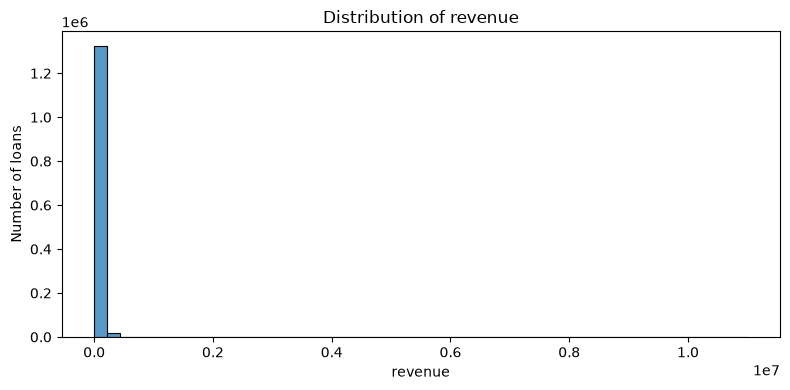

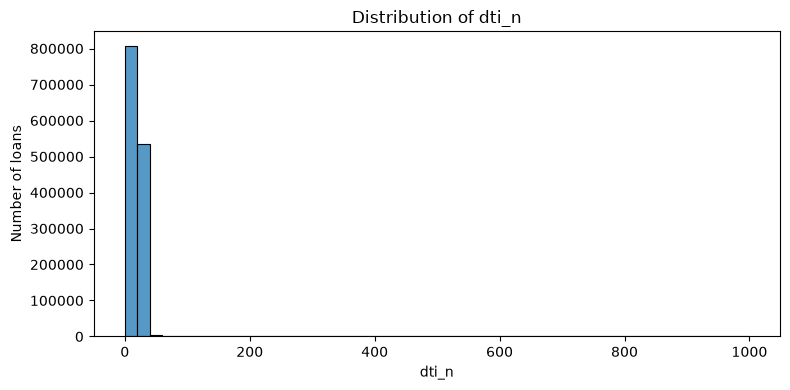

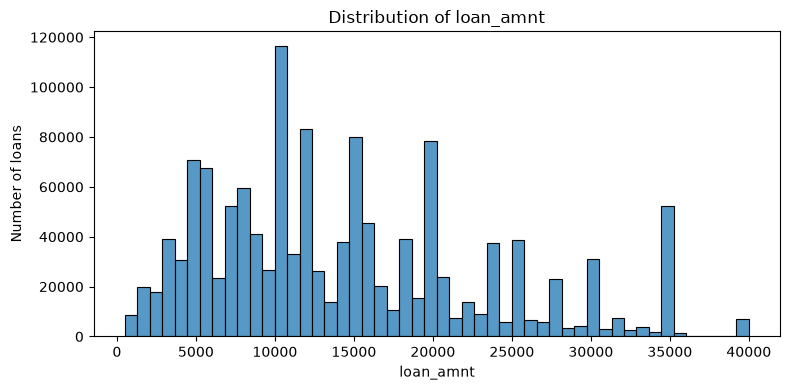

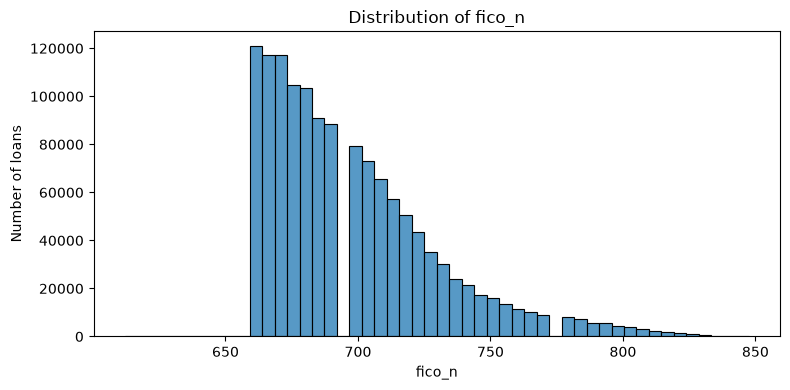

In [17]:
numerical_columns = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n"
]

for col in numerical_columns:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=col,
        bins=50
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of loans")

    plt.tight_layout()
    plt.show()

#### default rates across loan purposes

In [18]:
purpose_default = (
    df.groupby("purpose")["Default"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)

purpose_default["mean"] = purpose_default["mean"] * 100

purpose_default = purpose_default.rename(
    columns={
        "mean": "Default_Rate_Percent",
        "count": "Loan_Count"
    }
)

display(purpose_default.round(2))

,Default_Rate_Percent,Loan_Count
purpose,,
small_business,29.86,15575
renewable_energy,23.72,936
moving,23.41,9520
house,21.91,7294
medical,21.84,15606
debt_consolidation,21.15,781206
other,21.08,78263
educational,20.80,423
vacation,19.19,9083


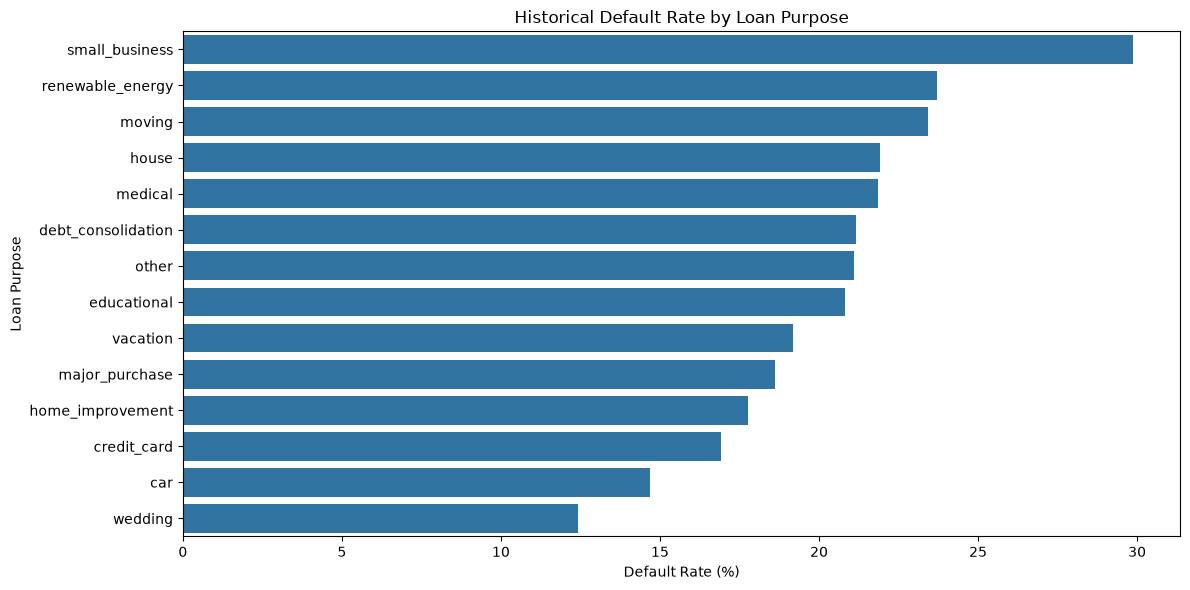

In [19]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=purpose_default.reset_index(),
    x="Default_Rate_Percent",
    y="purpose"
)

plt.title("Historical Default Rate by Loan Purpose")
plt.xlabel("Default Rate (%)")
plt.ylabel("Loan Purpose")
plt.tight_layout()
plt.show()

Compare default rates by home ownership

In [20]:
ownership_default = (
    df.groupby("home_ownership_n")["Default"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)

ownership_default["mean"] *= 100

ownership_default = ownership_default.rename(
    columns={
        "mean": "Default_Rate_Percent",
        "count": "Loan_Count"
    }
)

display(ownership_default.round(2))

,Default_Rate_Percent,Loan_Count
home_ownership_n,,
RENT,23.23,535585
OWN,20.63,144985
OTHER,19.73,517
MORTGAGE,17.23,666594


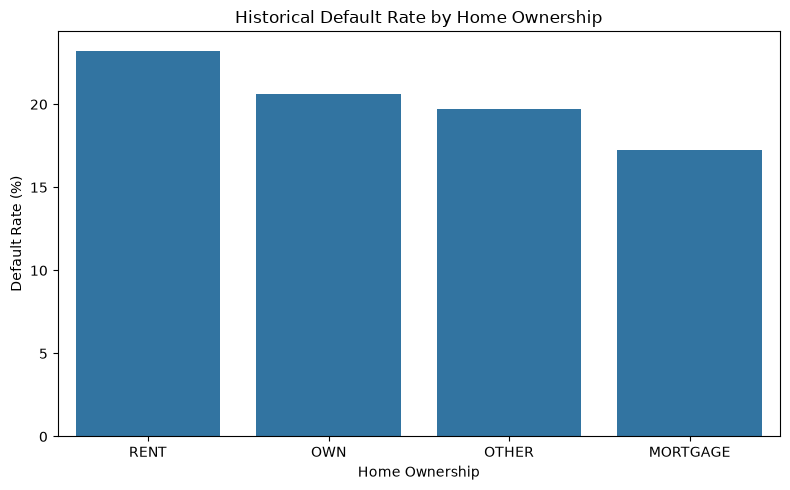

In [21]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=ownership_default.reset_index(),
    x="home_ownership_n",
    y="Default_Rate_Percent"
)

plt.title("Historical Default Rate by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()

Correlation

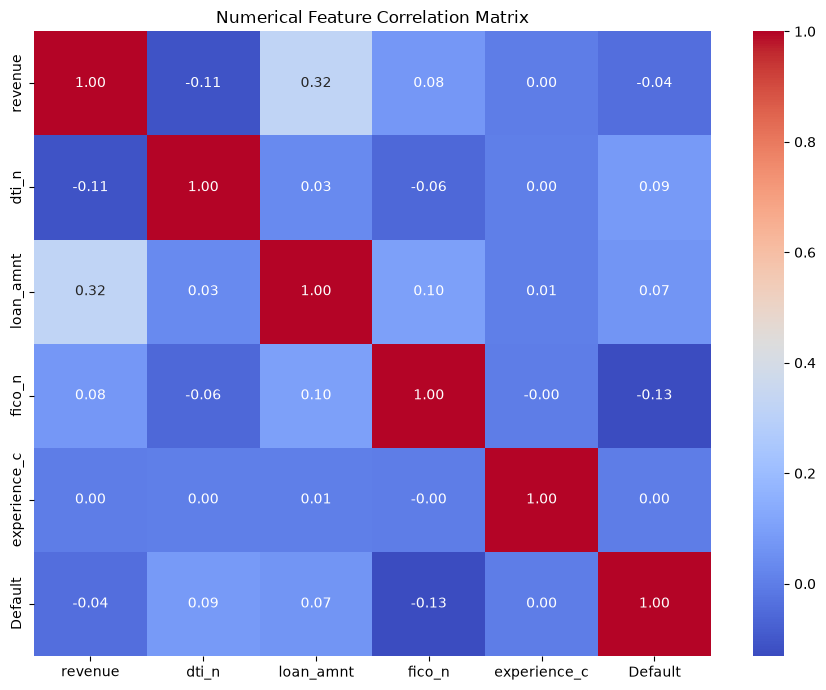

In [22]:
numerical_columns = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n",
    "experience_c",
    "Default"
]

correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.show()

Default rate with sample sizes

In [23]:
purpose_analysis = df.groupby("purpose").agg(
    Total_Loans=("Default", "count"),
    Defaults=("Default", "sum"),
    Default_Rate=("Default", "mean")
)

purpose_analysis["Default_Rate"] *= 100

purpose_analysis = purpose_analysis.sort_values(
    "Default_Rate",
    ascending=False
)

display(purpose_analysis.round(2))

,Total_Loans,Defaults,Default_Rate
purpose,,,
small_business,15575,4650,29.86
renewable_energy,936,222,23.72
moving,9520,2229,23.41
house,7294,1598,21.91
medical,15606,3409,21.84
debt_consolidation,781206,165258,21.15
other,78263,16501,21.08
educational,423,88,20.80
vacation,9083,1743,19.19


### extreme values

Inspect extreme DTI records

In [24]:
dti_extreme = df[df["dti_n"] > 50]

print("Records with DTI above 50:", len(dti_extreme))

display(
    dti_extreme[
        ["revenue", "dti_n", "loan_amnt", "fico_n", "Default"]
    ].head(20)
)

Records with DTI above 50: 2780


,revenue,dti_n,loan_amnt,fico_n,Default
2400,120000.0,51.20,26600,687.0,0
4026,110486.0,83.64,25000,682.0,0
7767,62151.0,999.00,6550,672.0,0
8924,98000.0,83.40,15400,662.0,0
9396,175000.0,137.40,15000,702.0,0
10571,103561.8,89.83,28000,672.0,0
15041,52000.0,52.80,18200,702.0,0
17316,182407.0,58.54,35000,697.0,0
17564,78200.0,59.18,5000,717.0,0
18478,93000.0,59.26,26050,667.0,1


Inspect extreme income records

In [25]:
income_extreme = df[df["revenue"] > 500000]

print("Records with income above 500000:", len(income_extreme))

display(
    income_extreme[
        ["revenue", "dti_n", "loan_amnt", "fico_n", "Default"]
    ].head(20)
)

Records with income above 500000: 1789


,revenue,dti_n,loan_amnt,fico_n,Default
1297,650000.0,7.13,35000,762.0,0
2594,525000.0,5.14,24000,667.0,0
3002,675000.0,13.44,27025,702.0,0
3292,520000.0,18.53,35000,712.0,0
4204,600000.0,11.02,16000,662.0,0
4739,550000.0,12.64,20225,702.0,0
5197,600000.0,7.77,28000,747.0,0
5713,750000.0,3.64,15000,722.0,0
6219,1400000.0,0.07,16000,787.0,0
6460,3964280.0,0.05,1225,742.0,0


Investigate DTI = 999

In [26]:
print("DTI = 999 records:")
display(
    df[df["dti_n"] == 999][
        ["revenue", "dti_n", "loan_amnt", "fico_n", "Default"]
    ]
)

print("\nDTI above 100:")
print((df["dti_n"] > 100).sum())

print("\nDTI between 50 and 100:")
print(((df["dti_n"] > 50) & (df["dti_n"] <= 100)).sum())

DTI = 999 records:


,revenue,dti_n,loan_amnt,fico_n,Default
7767,62151.0,999.0,6550,672.0,0
381305,78800.0,999.0,8000,687.0,0
386273,66633.0,999.0,10250,712.0,0
394079,126665.0,999.0,14225,752.0,0
398115,58800.0,999.0,15000,717.0,0
398172,153000.0,999.0,26000,762.0,0
402650,76000.0,999.0,21000,692.0,0
404149,138100.0,999.0,10000,722.0,0
411443,160300.0,999.0,35000,672.0,0
417509,145600.0,999.0,35000,677.0,1



DTI above 100:
533

DTI between 50 and 100:
2247


In [28]:
# Replace the special DTI value 999 with NaN
df["dti_n"] = df["dti_n"].replace(999, np.nan)

print("DTI cleaning completed!")

print("Missing DTI values:", df["dti_n"].isnull().sum())

print("\nDTI statistics:")
print(df["dti_n"].describe())

DTI cleaning completed!
Missing DTI values: 38

DTI statistics:
count    1.347643e+06
mean     1.827144e+01
std      9.861714e+00
min      0.000000e+00
25%      1.182000e+01
50%      1.763000e+01
75%      2.407000e+01
max      9.915700e+02
Name: dti_n, dtype: float64


In [27]:
print("Revenue percentiles:")

print(
    df["revenue"].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1.00]
    )
)

print("\nRevenue above 1 million:")
print((df["revenue"] > 1000000).sum())

Revenue percentiles:
0.500       65000.0
0.750       92000.0
0.900      129000.0
0.950      160000.0
0.990      260000.0
0.995      325000.0
0.999      585000.0
1.000    10999200.0
Name: revenue, dtype: float64

Revenue above 1 million:
294


### Features

In [29]:
df["issue_year"] = df["issue_d"].dt.year
df["issue_month"] = df["issue_d"].dt.month

print("Date feature extraction completed!")

display(
    df[["issue_d", "issue_year", "issue_month"]].head()
)

print("\nIssue year distribution:")
print(df["issue_year"].value_counts().sort_index())

Date feature extraction completed!


,issue_d,issue_year,issue_month
0,2015-12-01,2015,12
1,2015-12-01,2015,12
2,2015-12-01,2015,12
3,2015-12-01,2015,12
4,2015-12-01,2015,12



Issue year distribution:
issue_year
2007       599
2008      2393
2009      5281
2010     12537
2011     21721
2012     53367
2013    134804
2014    223102
2015    375543
2016    293057
2017    169117
2018     56160
Name: count, dtype: int64


In [30]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (1347681, 17)

Missing values:
id                        0
issue_d                   0
revenue                   0
dti_n                    38
loan_amnt                 0
fico_n                    0
experience_c              0
emp_length                0
purpose                   0
home_ownership_n          0
addr_state                0
zip_code                  1
Default                   0
title                 16657
desc                1228582
issue_year                0
issue_month               0
dtype: int64

Data types:
id                           int64
issue_d             datetime64[us]
revenue                    float64
dti_n                      float64
loan_amnt                    int64
fico_n                     float64
experience_c                 int64
emp_length                     str
purpose                        str
home_ownership_n               str
addr_state                     str
zip_code                       str
Default                      int

In [31]:
numerical_features = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n",
    "experience_c",
    "issue_year",
    "issue_month"
]

categorical_features = [
    "emp_length",
    "purpose",
    "home_ownership_n"
]

feature_columns = numerical_features + categorical_features

X = df[feature_columns].copy()

# Preserve historical outcomes separately
y_default = df["Default"].copy()

print("Clustering dataset shape:", X.shape)

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nDefault kept separately:", y_default.shape)

Clustering dataset shape: (1347681, 10)

Numerical features:
['revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'issue_year', 'issue_month']

Categorical features:
['emp_length', 'purpose', 'home_ownership_n']

Default kept separately: (1347681,)


Transform revenue

In [32]:
X["revenue"] = np.log1p(X["revenue"])

print("Revenue transformation completed!")

display(X["revenue"].describe())

Revenue transformation completed!


count    1.347681e+06
mean     1.109949e+01
std      5.383695e-01
min      7.548029e+00
25%      1.074938e+01
50%      1.108216e+01
75%      1.142955e+01
max      1.621333e+01
Name: revenue, dtype: float64

Encode categorical features

In [33]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore")

X_encoded = encoder.fit_transform(
    X[categorical_features]
)

print("Categorical encoding completed!")
print("Encoded shape:", X_encoded.shape)

Categorical encoding completed!
Encoded shape: (1347681, 30)


In [34]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_num_imputed = imputer.fit_transform(
    X[numerical_features]
)

print("Missing numerical values handled!")
print("Shape:", X_num_imputed.shape)

Missing numerical values handled!
Shape: (1347681, 7)


Scale numerical features

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_num_scaled = scaler.fit_transform(
    X_num_imputed
)

print("Numerical scaling completed!")

print("Scaled shape:", X_num_scaled.shape)

Numerical scaling completed!
Scaled shape: (1347681, 7)


Combine encoded and scaled features

In [36]:
from scipy.sparse import hstack, csr_matrix

X_processed = hstack(
    [
        csr_matrix(X_num_scaled),
        X_encoded
    ],
    format="csr"
)

print("Final preprocessing completed!")

print("Final X shape:", X_processed.shape)
print("Number of borrowers:", X_processed.shape[0])
print("Number of features:", X_processed.shape[1])

Final preprocessing completed!
Final X shape: (1347681, 37)
Number of borrowers: 1347681
Number of features: 37


In [37]:
print("Missing values in numerical features:",
      np.isnan(X_num_scaled).sum())

print("Sparse matrix:", X_processed)

print("\nDefault values kept separately:")
print(y_default.value_counts())

Missing values in numerical features: 0
Sparse matrix: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 13476810 stored elements and shape (1347681, 37)>
  Coords	Values
  (0, 0)	-0.34248756005455316
  (0, 1)	-1.2534937691145382
  (0, 2)	-1.2401381194473466
  (0, 3)	-0.6643572135148156
  (0, 4)	0.0043070556159535145
  (0, 5)	0.02493167590997572
  (0, 6)	1.5915904291748373
  (0, 8)	1.0
  (0, 21)	1.0
  (0, 33)	1.0
  (1, 0)	-0.03219632863623215
  (1, 1)	-0.22424613009439523
  (1, 2)	1.1808793028344833
  (1, 3)	0.5915805050337994
  (1, 4)	0.0043070556159535145
  (1, 5)	0.02493167590997572
  (1, 6)	1.5915904291748373
  (1, 8)	1.0
  (1, 30)	1.0
  (1, 33)	1.0
  (2, 0)	0.13180132022291083
  (2, 1)	-0.44834832538843616
  (2, 2)	0.6416005405252605
  (2, 3)	-0.03638835424050804
  (2, 4)	0.0043070556159535145
  :	:
  (1347678, 5)	0.626671457456483
  (1347678, 6)	1.0119022318052773
  (1347678, 10)	1.0
  (1347678, 23)	1.0
  (1347678, 33)	1.0
  (1347679, 0)	1.521085468822355
  (1347679, 

### K-Means Clustering

In [38]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [39]:
np.random.seed(42)

sample_indices = np.random.choice(
    X_processed.shape[0],
    size=50000,
    replace=False
)

X_sample = X_processed[sample_indices]

print("Sample created successfully!")
print("Sample shape:", X_sample.shape)

Sample created successfully!
Sample shape: (50000, 37)


In [40]:
inertia_values = []

for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=5,
        max_iter=100
    )

    kmeans.fit(X_sample)

    inertia_values.append(kmeans.inertia_)

    print(f"K = {k}, Inertia = {kmeans.inertia_:.2f}")

K = 2, Inertia = 345440.04
K = 3, Inertia = 316794.15
K = 4, Inertia = 295624.81
K = 5, Inertia = 280629.63
K = 6, Inertia = 269586.05
K = 7, Inertia = 260665.00
K = 8, Inertia = 253419.60


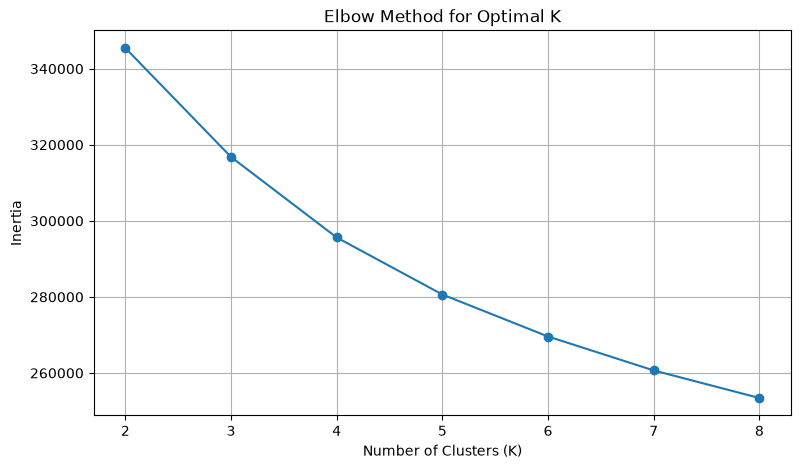

In [41]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 9),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(2, 9))
plt.grid(True)

plt.show()

In [42]:
silhouette_indices = np.random.choice(
    X_sample.shape[0],
    size=5000,
    replace=False
)

X_silhouette = X_sample[silhouette_indices]

silhouette_values = []

for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=5,
        max_iter=100
    )

    kmeans.fit(X_sample)

    labels = kmeans.labels_[silhouette_indices]

    score = silhouette_score(
        X_silhouette,
        labels
    )

    silhouette_values.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.1335
K = 3, Silhouette Score = 0.1082
K = 4, Silhouette Score = 0.1123
K = 5, Silhouette Score = 0.1064
K = 6, Silhouette Score = 0.0961
K = 7, Silhouette Score = 0.0915
K = 8, Silhouette Score = 0.0863


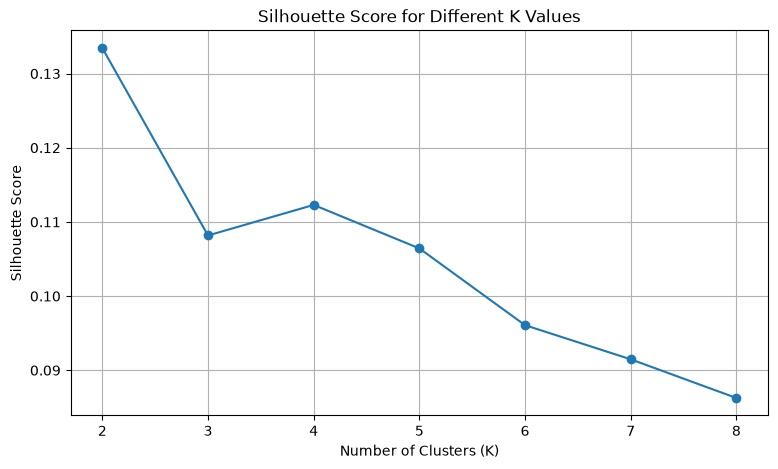

In [43]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 9),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(True)

plt.show()

Compare candidate clusters

In [44]:
cluster_results = {}

for k in [2, 3, 4]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=5,
        max_iter=100
    )

    labels = model.fit_predict(X_sample)

    sample_df = df.iloc[sample_indices].copy()
    sample_df["Cluster"] = labels

    cluster_summary = sample_df.groupby("Cluster").agg(
        Borrowers=("Default", "count"),
        Average_Income=("revenue", "mean"),
        Average_FICO=("fico_n", "mean"),
        Average_Loan=("loan_amnt", "mean"),
        Default_Rate=("Default", "mean")
    )

    cluster_results[k] = cluster_summary

    print(f"\n========== K = {k} ==========")
    display(cluster_summary.round(3))


========== K = 2 ==========


,Borrowers,Average_Income,Average_FICO,Average_Loan,Default_Rate
Cluster,,,,,
0,30516,54222.355,691.148,9503.855,0.207
1,19484,113885.166,709.353,22116.288,0.188



========== K = 3 ==========


,Borrowers,Average_Income,Average_FICO,Average_Loan,Default_Rate
Cluster,,,,,
0,17624,59832.514,692.457,10459.474,0.215
1,18403,58689.809,695.019,10425.534,0.189
2,13973,124456.536,709.784,24671.474,0.194



========== K = 4 ==========


,Borrowers,Average_Income,Average_FICO,Average_Loan,Default_Rate
Cluster,,,,,
0,16457,58326.206,686.740,10497.870,0.207
1,6409,79695.428,758.599,13198.576,0.096
2,15490,59393.800,686.492,10403.560,0.221
3,11644,127356.203,696.909,25972.956,0.217


Detailed K=4

In [46]:
# Train K-Means with 4 clusters
kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=5,
    max_iter=100
)

labels_4 = kmeans_4.fit_predict(X_sample)

# Create a profiling dataframe
profile_df = df.iloc[sample_indices].copy()
profile_df["Cluster"] = labels_4

# Summarize the clusters
profile = profile_df.groupby("Cluster").agg(
    Borrowers=("Default", "count"),
    Average_Income=("revenue", "mean"),
    Average_FICO=("fico_n", "mean"),
    Average_Loan=("loan_amnt", "mean"),
    Average_DTI=("dti_n", "mean"),
    Default_Rate=("Default", "mean"),
    Top_Purpose=("purpose", lambda x: x.mode().iloc[0]),
    Top_Ownership=("home_ownership_n", lambda x: x.mode().iloc[0])
)

profile["Borrower_Percentage"] = (
    profile["Borrowers"] / len(profile_df) * 100
)

display(profile.round(3))

,Borrowers,Average_Income,Average_FICO,Average_Loan,Average_DTI,Default_Rate,Top_Purpose,Top_Ownership,Borrower_Percentage
Cluster,,,,,,,,,
0,16457,58326.206,686.740,10497.870,18.702,0.207,debt_consolidation,RENT,32.914
1,6409,79695.428,758.599,13198.576,14.808,0.096,debt_consolidation,MORTGAGE,12.818
2,15490,59393.800,686.492,10403.560,19.512,0.221,debt_consolidation,RENT,30.980
3,11644,127356.203,696.909,25972.956,17.770,0.217,debt_consolidation,MORTGAGE,23.288


Detailed cluster comparison

In [47]:
# Compare numerical characteristics
comparison = profile_df.groupby("Cluster").agg(
    Median_Income=("revenue", "median"),
    Median_FICO=("fico_n", "median"),
    Median_Loan=("loan_amnt", "median"),
    Median_DTI=("dti_n", "median"),
    Default_Rate=("Default", "mean")
)

display(comparison.round(3))

# Compare employment length
print("Employment Length Distribution:")
display(pd.crosstab(
    profile_df["Cluster"],
    profile_df["emp_length"],
    normalize="index"
).round(3))

# Compare loan purpose
print("Loan Purpose Distribution:")
display(pd.crosstab(
    profile_df["Cluster"],
    profile_df["purpose"],
    normalize="index"
).round(3))

,Median_Income,Median_FICO,Median_Loan,Median_DTI,Default_Rate
Cluster,,,,,
0,54000.0,682.0,10000.0,18.36,0.207
1,70000.0,752.0,12000.0,14.04,0.096
2,55000.0,682.0,10000.0,18.87,0.221
3,108000.0,692.0,25000.0,16.95,0.217


Employment Length Distribution:


emp_length,1 year,10+ years,2 years,3 years,4 years,5 years,6 years,7 years,8 years,9 years,< 1 year,NI
Cluster,,,,,,,,,,,,
0,0.073,0.291,0.094,0.084,0.063,0.065,0.048,0.047,0.047,0.035,0.089,0.064
1,0.063,0.337,0.086,0.079,0.057,0.067,0.047,0.039,0.044,0.042,0.075,0.063
2,0.071,0.295,0.100,0.084,0.060,0.061,0.046,0.044,0.042,0.037,0.085,0.074
3,0.051,0.420,0.081,0.073,0.056,0.058,0.047,0.044,0.039,0.037,0.070,0.024


Loan Purpose Distribution:


purpose,car,credit_card,debt_consolidation,educational,home_improvement,house,major_purchase,medical,moving,other,renewable_energy,small_business,vacation,wedding
Cluster,,,,,,,,,,,,,,
0,0.011,0.220,0.582,0.0,0.052,0.004,0.019,0.013,0.009,0.065,0.001,0.011,0.009,0.004
1,0.024,0.198,0.481,0.0,0.108,0.012,0.050,0.014,0.008,0.077,0.001,0.018,0.008,0.002
2,0.010,0.225,0.579,0.0,0.056,0.005,0.020,0.013,0.009,0.065,0.001,0.009,0.009,0.001
3,0.003,0.233,0.626,0.0,0.070,0.006,0.015,0.004,0.002,0.027,0.000,0.013,0.001,0.000


Compare Clusters 0 and 2

their differences

In [48]:
cluster_0_2 = profile_df[
    profile_df["Cluster"].isin([0, 2])
]

comparison_0_2 = cluster_0_2.groupby("Cluster").agg(
    Borrowers=("Default", "count"),
    Mean_Income=("revenue", "mean"),
    Median_Income=("revenue", "median"),
    Mean_FICO=("fico_n", "mean"),
    Median_FICO=("fico_n", "median"),
    Mean_Loan=("loan_amnt", "mean"),
    Median_Loan=("loan_amnt", "median"),
    Mean_DTI=("dti_n", "mean"),
    Median_DTI=("dti_n", "median"),
    Default_Rate=("Default", "mean")
)

display(comparison_0_2.round(3))

,Borrowers,Mean_Income,Median_Income,Mean_FICO,Median_FICO,Mean_Loan,Median_Loan,Mean_DTI,Median_DTI,Default_Rate
Cluster,,,,,,,,,,
0,16457,58326.206,54000.0,686.740,682.0,10497.87,10000.0,18.702,18.36,0.207
2,15490,59393.800,55000.0,686.492,682.0,10403.56,10000.0,19.512,18.87,0.221


Compare default rates

In [49]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    profile_df["Cluster"],
    profile_df["Default"]
).loc[[0, 2]]

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", round(chi2, 4))
print("P-value:", p_value)

if p_value < 0.05:
    print("The default-rate distributions differ statistically.")
else:
    print("No statistically significant difference detected.")

Chi-square statistic: 9.0745
P-value: 0.002591953507423767
The default-rate distributions differ statistically.


Cluster comparison plots

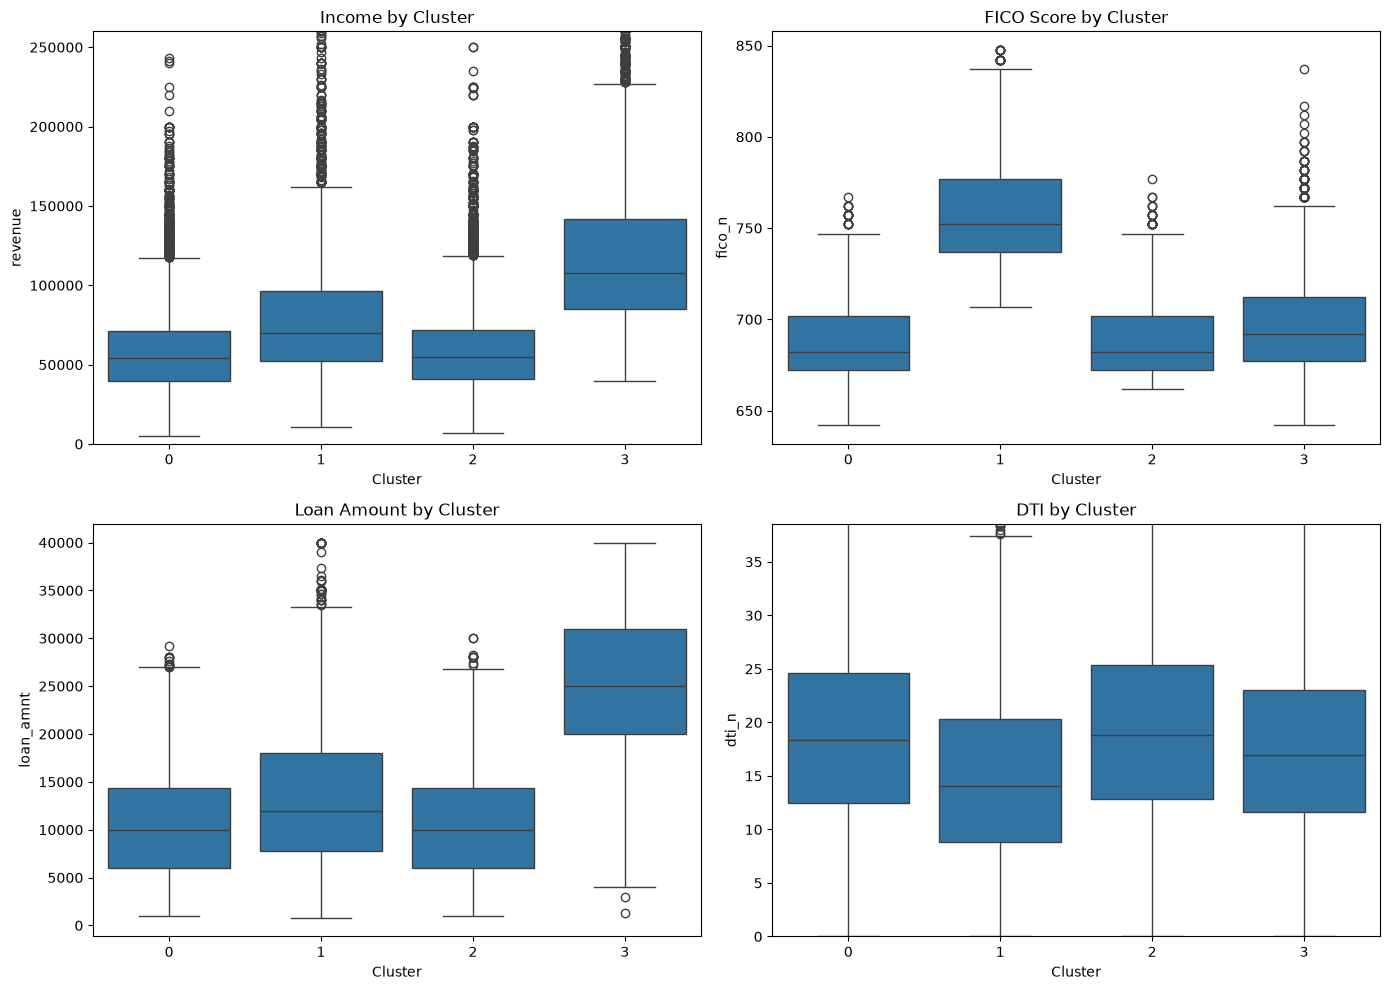

In [50]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=profile_df, x="Cluster", y="revenue", ax=axes[0, 0])
axes[0, 0].set_title("Income by Cluster")
axes[0, 0].set_ylim(0, profile_df["revenue"].quantile(0.99))

sns.boxplot(data=profile_df, x="Cluster", y="fico_n", ax=axes[0, 1])
axes[0, 1].set_title("FICO Score by Cluster")

sns.boxplot(data=profile_df, x="Cluster", y="loan_amnt", ax=axes[1, 0])
axes[1, 0].set_title("Loan Amount by Cluster")

sns.boxplot(data=profile_df, x="Cluster", y="dti_n", ax=axes[1, 1])
axes[1, 1].set_title("DTI by Cluster")
axes[1, 1].set_ylim(0, profile_df["dti_n"].quantile(0.99))

plt.tight_layout()
plt.show()

### PCA

In [51]:
from sklearn.decomposition import PCA

# Convert the sample to a dense matrix
X_sample_dense = X_sample.toarray()

# Apply PCA
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_sample_dense)

print("PCA completed!")
print("PCA shape:", X_pca.shape)

print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_
)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

PCA completed!
PCA shape: (50000, 2)
Explained variance ratio: [0.20529271 0.1481865 ]
Total explained variance: 0.353479210737803


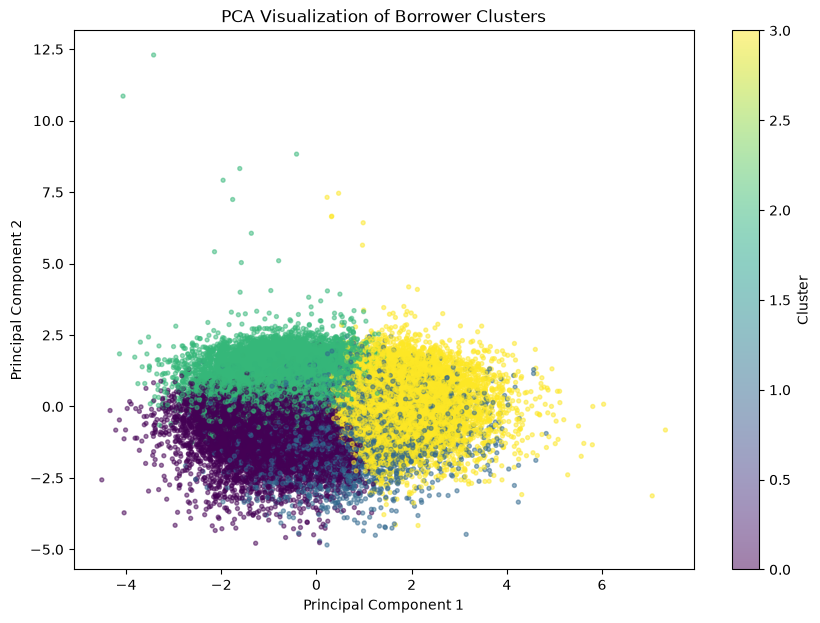

In [52]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_4,
    cmap="viridis",
    s=8,
    alpha=0.5
)

plt.title("PCA Visualization of Borrower Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")

plt.show()

### t-SNE visualization

In [53]:
from sklearn.manifold import TSNE

# Select 10,000 borrowers from our existing sample
np.random.seed(42)

tsne_indices = np.random.choice(
    X_sample.shape[0],
    size=10000,
    replace=False
)

X_tsne_sample = X_sample_dense[tsne_indices]

# Apply t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42,
    max_iter=1000
)

X_tsne = tsne.fit_transform(X_tsne_sample)

print("t-SNE completed!")
print("t-SNE shape:", X_tsne.shape)

t-SNE completed!
t-SNE shape: (10000, 2)


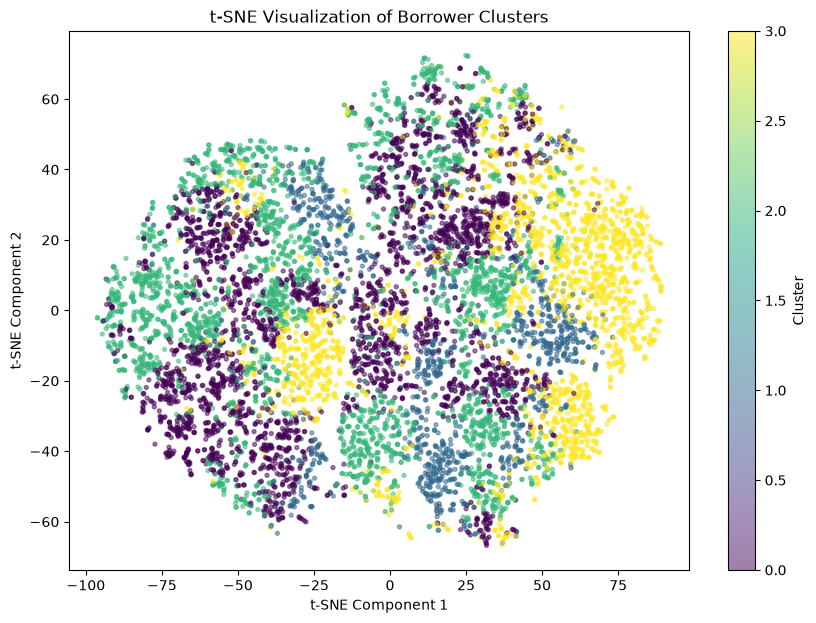

In [54]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=labels_4[tsne_indices],
    cmap="viridis",
    s=8,
    alpha=0.5
)

plt.title("t-SNE Visualization of Borrower Clusters")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.colorbar(label="Cluster")

plt.show()

### Hierarchical Clustering

In [55]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Select 5,000 borrowers
np.random.seed(42)

hier_indices = np.random.choice(
    X_sample.shape[0],
    size=5000,
    replace=False
)

X_hier = X_sample_dense[hier_indices]

print("Hierarchical sample shape:", X_hier.shape)

Hierarchical sample shape: (5000, 37)


In [56]:
hierarchical = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
)

hier_labels = hierarchical.fit_predict(X_hier)

print("Hierarchical clustering completed!")
print("Number of clusters:", len(np.unique(hier_labels)))

print("\nCluster distribution:")
print(pd.Series(hier_labels).value_counts().sort_index())

Hierarchical clustering completed!
Number of clusters: 4

Cluster distribution:
0    2545
1    1177
2     506
3     772
Name: count, dtype: int64


In [57]:
hier_score = silhouette_score(
    X_hier,
    hier_labels
)

print("Hierarchical Silhouette Score:", round(hier_score, 4))

Hierarchical Silhouette Score: 0.0645


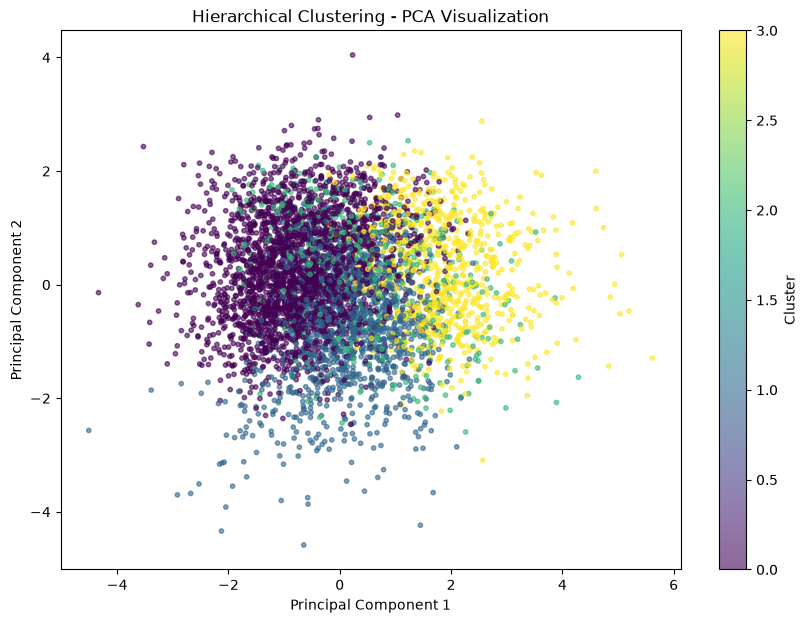

In [58]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[hier_indices, 0],
    X_pca[hier_indices, 1],
    c=hier_labels,
    cmap="viridis",
    s=10,
    alpha=0.6
)

plt.title("Hierarchical Clustering - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")

plt.show()

K-Means vs Hierarchical comparison

In [59]:
# K-Means labels for the same 5,000 records
kmeans_labels_comparison = labels_4[hier_indices]

# Calculate both scores on identical records
kmeans_comparison_score = silhouette_score(
    X_hier,
    kmeans_labels_comparison
)

hierarchical_comparison_score = silhouette_score(
    X_hier,
    hier_labels
)

comparison_results = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical"],
    "Silhouette Score": [
        kmeans_comparison_score,
        hierarchical_comparison_score
    ]
})

display(comparison_results.round(4))

,Algorithm,Silhouette Score
0,K-Means,0.1115
1,Hierarchical,0.0645


### DBSCAN

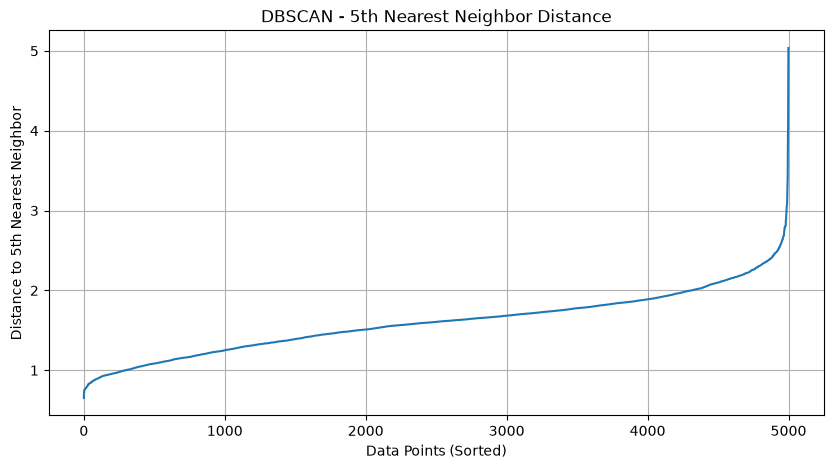

In [60]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# Use the same 5,000-record sample
neighbors = NearestNeighbors(n_neighbors=5)

neighbors.fit(X_hier)

distances, indices = neighbors.kneighbors(X_hier)

# Sort distance to the 5th nearest neighbor
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.title("DBSCAN - 5th Nearest Neighbor Distance")
plt.xlabel("Data Points (Sorted)")
plt.ylabel("Distance to 5th Nearest Neighbor")
plt.grid(True)

plt.show()

In [61]:
dbscan = DBSCAN(
    eps=2.5,
    min_samples=5,
    metric="euclidean"
)

dbscan_labels = dbscan.fit_predict(X_hier)

print("DBSCAN completed!")

unique_labels = set(dbscan_labels)

n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
n_noise = np.sum(dbscan_labels == -1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("Noise percentage:", round(n_noise / len(dbscan_labels) * 100, 2), "%")

print("\nCluster distribution:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

DBSCAN completed!
Number of clusters: 1
Number of noise points: 27
Noise percentage: 0.54 %

Cluster distribution:
-1      27
 0    4973
Name: count, dtype: int64


In [62]:
clustered_mask = dbscan_labels != -1

dbscan_cluster_labels = dbscan_labels[clustered_mask]
X_dbscan_clustered = X_hier[clustered_mask]

if len(np.unique(dbscan_cluster_labels)) >= 2:

    dbscan_score = silhouette_score(
        X_dbscan_clustered,
        dbscan_cluster_labels
    )

    print("DBSCAN Silhouette Score:", round(dbscan_score, 4))

else:
    dbscan_score = None
    print("Silhouette Score cannot be calculated.")

Silhouette Score cannot be calculated.


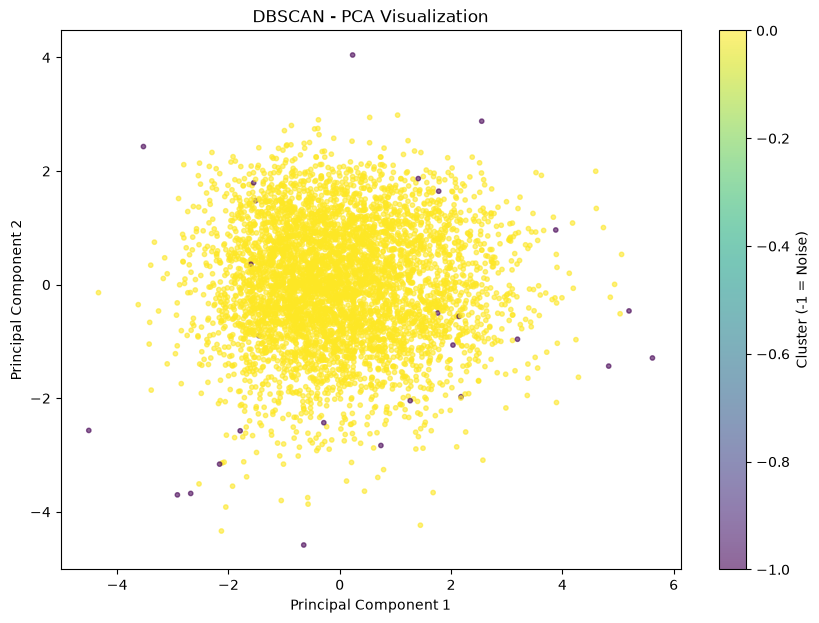

In [63]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[hier_indices, 0],
    X_pca[hier_indices, 1],
    c=dbscan_labels,
    cmap="viridis",
    s=10,
    alpha=0.6
)

plt.title("DBSCAN - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster (-1 = Noise)")

plt.show()

DBSCAN parameter experimentation

In [64]:
eps_values = [1.2, 1.4, 1.6, 1.8, 2.0, 2.2]

dbscan_results = []

for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=5,
        metric="euclidean"
    )

    labels = model.fit_predict(X_hier)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = np.sum(labels == -1)

    score = None

    mask = labels != -1
    valid_labels = labels[mask]

    if len(np.unique(valid_labels)) >= 2:
        score = silhouette_score(
            X_hier[mask],
            valid_labels
        )

    dbscan_results.append({
        "Epsilon": eps,
        "Clusters": n_clusters,
        "Noise Points": n_noise,
        "Noise Percentage": round(n_noise / len(labels) * 100, 2),
        "Silhouette Score": score
    })

dbscan_comparison = pd.DataFrame(dbscan_results)

display(dbscan_comparison)

,Epsilon,Clusters,Noise Points,Noise Percentage,Silhouette Score
0,1.2,47,3594,71.88,-0.045821
1,1.4,55,2773,55.46,-0.064019
2,1.6,9,1686,33.72,-0.163068
3,1.8,1,709,14.18,NaN
4,2.0,1,304,6.08,NaN
5,2.2,1,124,2.48,NaN


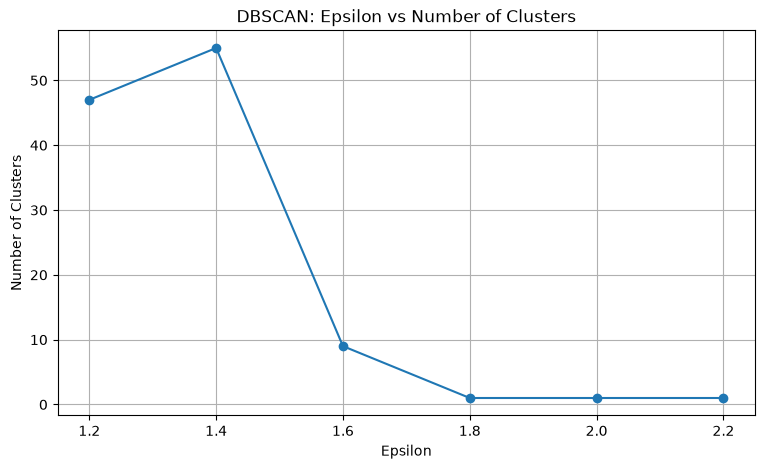

In [65]:
plt.figure(figsize=(9, 5))

plt.plot(
    dbscan_comparison["Epsilon"],
    dbscan_comparison["Clusters"],
    marker="o"
)

plt.title("DBSCAN: Epsilon vs Number of Clusters")
plt.xlabel("Epsilon")
plt.ylabel("Number of Clusters")
plt.grid(True)

plt.show()

PCA dimensionality reduction

In [66]:
from sklearn.decomposition import PCA

pca_dbscan = PCA(
    n_components=0.80,
    random_state=42
)

X_dbscan_pca = pca_dbscan.fit_transform(X_hier)

print("Original dimensions:", X_hier.shape[1])
print("Reduced dimensions:", X_dbscan_pca.shape[1])

print(
    "Explained variance:",
    round(pca_dbscan.explained_variance_ratio_.sum(), 4)
)

Original dimensions: 37
Reduced dimensions: 7
Explained variance: 0.8028


In [67]:
eps_values = [1.0, 1.5, 2.0, 2.5, 3.0]

pca_dbscan_results = []

for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_dbscan_pca)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = np.sum(labels == -1)

    mask = labels != -1
    valid_labels = labels[mask]

    score = None

    if len(np.unique(valid_labels)) >= 2:
        score = silhouette_score(
            X_dbscan_pca[mask],
            valid_labels
        )

    pca_dbscan_results.append({
        "Epsilon": eps,
        "Clusters": n_clusters,
        "Noise Points": n_noise,
        "Noise Percentage": round(n_noise / len(labels) * 100, 2),
        "Silhouette Score": score
    })

display(pd.DataFrame(pca_dbscan_results))

,Epsilon,Clusters,Noise Points,Noise Percentage,Silhouette Score
0,1.0,7,995,19.90,-0.042073
1,1.5,1,78,1.56,NaN
2,2.0,1,14,0.28,NaN
3,2.5,1,5,0.10,NaN
4,3.0,1,4,0.08,NaN


### Final K-Means evaluation

In [68]:
final_k_results = []

for k in [2, 3, 4]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=5,
        max_iter=100
    )

    labels = model.fit_predict(X_hier)

    score = silhouette_score(
        X_hier,
        labels
    )

    final_k_results.append({
        "K": k,
        "Silhouette Score": score,
        "Inertia": model.inertia_
    })

final_k_comparison = pd.DataFrame(final_k_results)

display(final_k_comparison.round(4))

,K,Silhouette Score,Inertia
0,2,0.1343,33677.8151
1,3,0.1077,30870.3762
2,4,0.1119,28680.1647


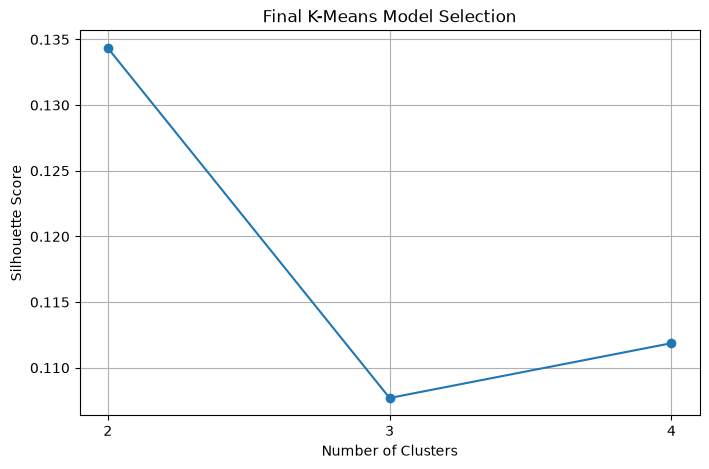

In [69]:
plt.figure(figsize=(8, 5))

plt.plot(
    final_k_comparison["K"],
    final_k_comparison["Silhouette Score"],
    marker="o"
)

plt.title("Final K-Means Model Selection")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks([2, 3, 4])
plt.grid(True)

plt.show()

K=2 vs K=4 profiling

In [70]:
# Train both models on the same sample
model_k2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=5
)

model_k4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=5
)

labels_k2 = model_k2.fit_predict(X_sample)
labels_k4 = model_k4.fit_predict(X_sample)

# Create comparison dataframe
comparison_df = df.iloc[sample_indices].copy()

comparison_df["Cluster_K2"] = labels_k2
comparison_df["Cluster_K4"] = labels_k4

# K=2 profile
print("K=2 BORROWER PROFILE")

display(
    comparison_df.groupby("Cluster_K2").agg(
        Borrowers=("Default", "count"),
        Average_Income=("revenue", "mean"),
        Average_FICO=("fico_n", "mean"),
        Average_Loan=("loan_amnt", "mean"),
        Average_DTI=("dti_n", "mean"),
        Default_Rate=("Default", "mean")
    ).round(3)
)

# K=4 profile
print("K=4 BORROWER PROFILE")

display(
    comparison_df.groupby("Cluster_K4").agg(
        Borrowers=("Default", "count"),
        Average_Income=("revenue", "mean"),
        Average_FICO=("fico_n", "mean"),
        Average_Loan=("loan_amnt", "mean"),
        Average_DTI=("dti_n", "mean"),
        Default_Rate=("Default", "mean")
    ).round(3)
)

K=2 BORROWER PROFILE


,Borrowers,Average_Income,Average_FICO,Average_Loan,Average_DTI,Default_Rate
Cluster_K2,,,,,,
0,30516,54222.355,691.148,9503.855,19.005,0.207
1,19484,113885.166,709.353,22116.288,17.034,0.188


K=4 BORROWER PROFILE


,Borrowers,Average_Income,Average_FICO,Average_Loan,Average_DTI,Default_Rate
Cluster_K4,,,,,,
0,16457,58326.206,686.740,10497.870,18.702,0.207
1,6409,79695.428,758.599,13198.576,14.808,0.096
2,15490,59393.800,686.492,10403.560,19.512,0.221
3,11644,127356.203,696.909,25972.956,17.770,0.217


K=2
- Cluster 0: lower average income and smaller loans.
- Cluster 1: higher average income and larger loans.
- Default rates are fairly close: 20.7% vs 18.8%.

K=4
- Cluster 1 stands out: FICO 758.6, DTI 14.8 and default rate 9.6%.
- Cluster 3 has the largest average loans and a 21.7% default rate.
- Clusters 0 and 2 remain very similar, which is a limitation.

K=4 for business segmentation

### Train K=4 on the full dataset

In [71]:
from sklearn.cluster import MiniBatchKMeans

final_kmeans = MiniBatchKMeans(
    n_clusters=4,
    random_state=42,
    batch_size=4096,
    n_init=3,
    max_iter=100
)

final_labels = final_kmeans.fit_predict(X_processed)

print("Full dataset clustering completed!")
print("Total borrowers:", len(final_labels))
print("Number of clusters:", len(np.unique(final_labels)))

print("\nCluster distribution:")
print(pd.Series(final_labels).value_counts().sort_index())

Full dataset clustering completed!
Total borrowers: 1347681
Number of clusters: 4

Cluster distribution:
0    346536
1    313535
2    391544
3    296066
Name: count, dtype: int64


In [72]:
df_clustered = df.copy()

df_clustered["Cluster"] = final_labels

print("Cluster labels attached successfully!")
display(df_clustered.head())

Cluster labels attached successfully!


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc,issue_year,issue_month,Cluster
0,68407277,2015-12-01,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN,2015,12,0
1,68355089,2015-12-01,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN,2015,12,0
2,68341763,2015-12-01,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN,2015,12,0
3,68476807,2015-12-01,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN,2015,12,0
4,68426831,2015-12-01,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN,2015,12,3


In [73]:
final_profile = df_clustered.groupby("Cluster").agg(
    Borrowers=("Default", "count"),
    Average_Income=("revenue", "mean"),
    Average_FICO=("fico_n", "mean"),
    Average_Loan=("loan_amnt", "mean"),
    Average_DTI=("dti_n", "mean"),
    Default_Rate=("Default", "mean")
)

final_profile["Borrower_Percentage"] = (
    final_profile["Borrowers"] / len(df_clustered) * 100
)

display(final_profile.round(3))

,Borrowers,Average_Income,Average_FICO,Average_Loan,Average_DTI,Default_Rate,Borrower_Percentage
Cluster,,,,,,,
0,346536,78363.174,700.699,12434.929,18.696,0.194,25.714
1,313535,125621.740,706.117,25837.549,17.319,0.203,23.265
2,391544,50899.053,690.484,9474.398,20.759,0.228,29.053
3,296066,60114.839,696.908,11139.166,15.495,0.166,21.969


Default Pattern Analysis

In [74]:
# Overall portfolio default rate
overall_default_rate = df_clustered["Default"].mean()

# Cluster-level default analysis
risk_analysis = df_clustered.groupby("Cluster").agg(
    Borrowers=("Default", "count"),
    Defaults=("Default", "sum"),
    Default_Rate=("Default", "mean")
)

risk_analysis["Default_Rate_Percentage"] = (
    risk_analysis["Default_Rate"] * 100
)

risk_analysis["Difference_From_Portfolio"] = (
    risk_analysis["Default_Rate"] - overall_default_rate
) * 100

print(
    "Overall Portfolio Default Rate:",
    round(overall_default_rate * 100, 2), "%"
)

display(risk_analysis.round(3))

Overall Portfolio Default Rate: 19.98 %


,Borrowers,Defaults,Default_Rate,Default_Rate_Percentage,Difference_From_Portfolio
Cluster,,,,,
0,346536,67296,0.194,19.420,-0.559
1,313535,63634,0.203,20.296,0.317
2,391544,89200,0.228,22.782,2.803
3,296066,49119,0.166,16.591,-3.388


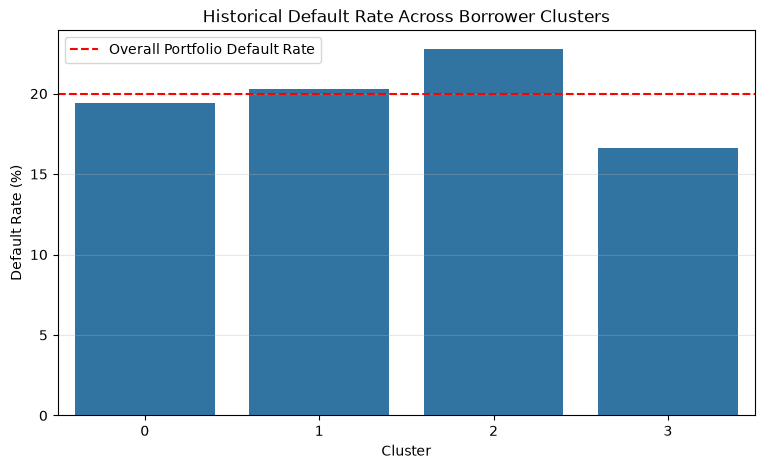

In [75]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=risk_analysis.index,
    y=risk_analysis["Default_Rate_Percentage"]
)

plt.axhline(
    overall_default_rate * 100,
    color="red",
    linestyle="--",
    label="Overall Portfolio Default Rate"
)

plt.title("Historical Default Rate Across Borrower Clusters")
plt.xlabel("Cluster")
plt.ylabel("Default Rate (%)")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

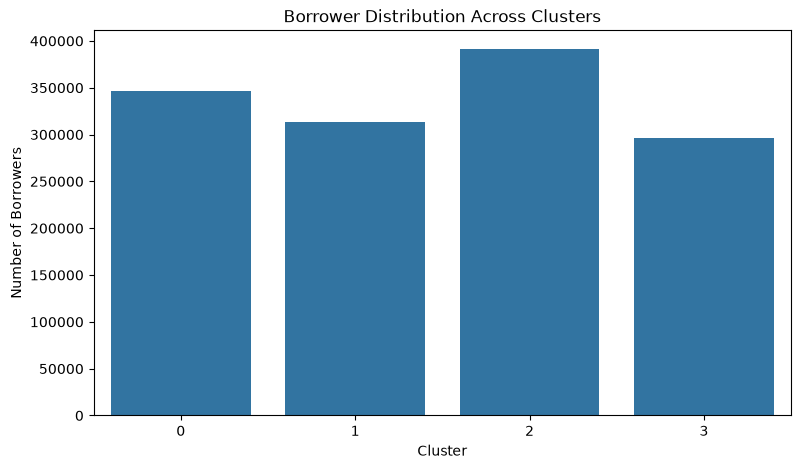

In [76]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=df_clustered["Cluster"].value_counts().sort_index().index,
    y=df_clustered["Cluster"].value_counts().sort_index().values
)

plt.title("Borrower Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Borrowers")

plt.show()

Default contribution analysis

In [77]:
default_contribution = df_clustered.groupby("Cluster").agg(
    Borrowers=("Default", "count"),
    Defaults=("Default", "sum")
)

default_contribution["Borrower_Share"] = (
    default_contribution["Borrowers"] /
    len(df_clustered) * 100
)

default_contribution["Default_Share"] = (
    default_contribution["Defaults"] /
    df_clustered["Default"].sum() * 100
)

default_contribution["Default_Rate"] = (
    default_contribution["Defaults"] /
    default_contribution["Borrowers"] * 100
)

display(default_contribution.round(2))

,Borrowers,Defaults,Borrower_Share,Default_Share,Default_Rate
Cluster,,,,,
0,346536,67296,25.71,24.99,19.42
1,313535,63634,23.26,23.63,20.30
2,391544,89200,29.05,33.13,22.78
3,296066,49119,21.97,18.24,16.59


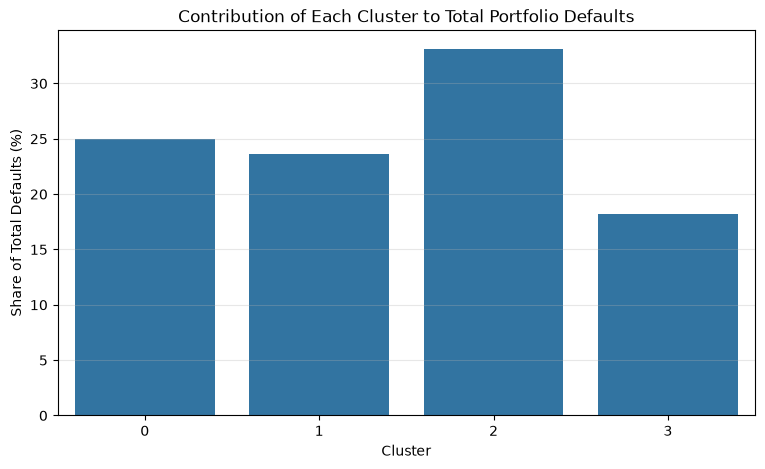

In [78]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=default_contribution.index,
    y=default_contribution["Default_Share"]
)

plt.title("Contribution of Each Cluster to Total Portfolio Defaults")
plt.xlabel("Cluster")
plt.ylabel("Share of Total Defaults (%)")

plt.grid(axis="y", alpha=0.3)
plt.show()

Default patterns by loan purpose

In [79]:
purpose_risk = df_clustered.pivot_table(
    index="Cluster",
    columns="purpose",
    values="Default",
    aggfunc="mean"
) * 100

display(purpose_risk.round(2))

purpose,car,credit_card,debt_consolidation,educational,home_improvement,house,major_purchase,medical,moving,other,renewable_energy,small_business,vacation,wedding
Cluster,,,,,,,,,,,,,,
0,12.72,16.56,20.87,NaN,16.98,21.54,18.04,20.12,21.73,19.74,29.50,31.91,16.02,0.00
1,18.04,16.22,21.24,0.0,19.48,20.76,24.97,24.19,24.97,23.76,16.36,31.61,30.96,18.55
2,18.47,19.95,24.06,0.0,19.63,25.67,20.02,24.98,27.16,23.13,23.76,31.15,22.19,20.29
3,11.55,13.85,17.58,21.0,14.18,19.42,13.14,18.07,19.12,18.28,21.20,26.06,15.71,11.84


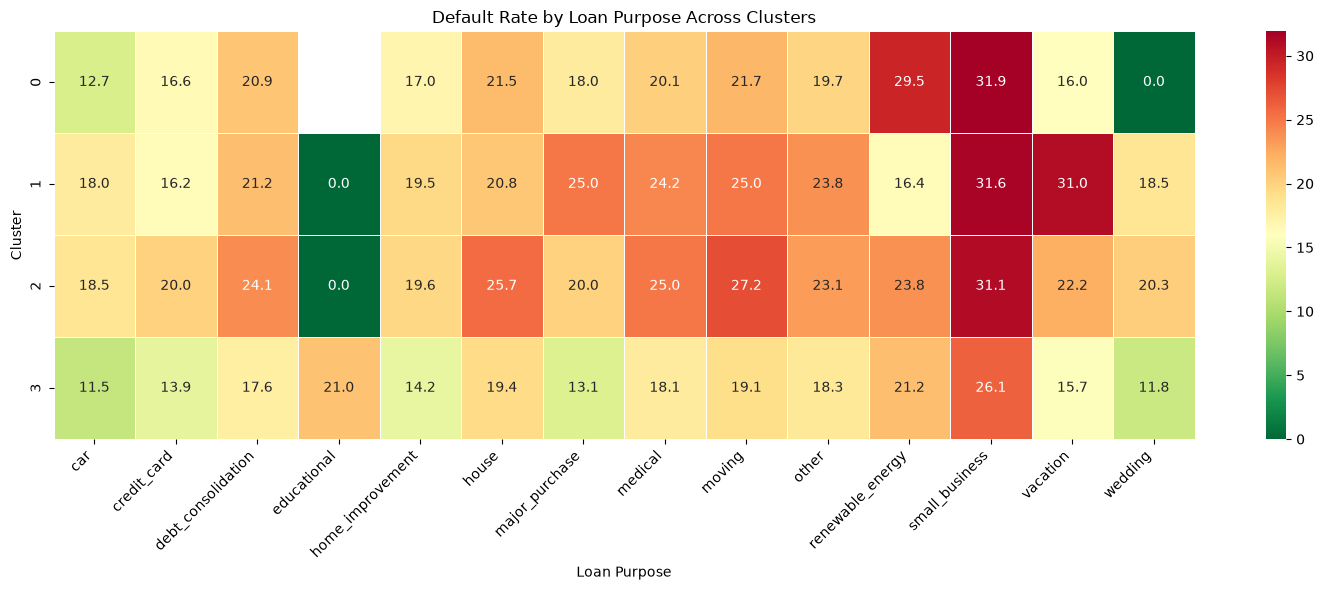

In [80]:
plt.figure(figsize=(15, 6))

sns.heatmap(
    purpose_risk,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    linewidths=0.5
)

plt.title("Default Rate by Loan Purpose Across Clusters")
plt.xlabel("Loan Purpose")
plt.ylabel("Cluster")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Cluster 2 has broader risk exposure
Some examples:
- Debt consolidation: 24.06%
- House: 25.67%
- Medical: 24.98%
- Moving: 27.16%

Cluster 3 performs better across several purposes
- Car: 11.55%
- Credit card: 13.85%
- Major purchase: 13.14%
- Wedding: 11.84%

statistical check

In [81]:
purpose_counts = df_clustered.pivot_table(
    index="Cluster",
    columns="purpose",
    values="Default",
    aggfunc="count",
    fill_value=0
)

display(purpose_counts)

purpose,car,credit_card,debt_consolidation,educational,home_improvement,house,major_purchase,medical,moving,other,renewable_energy,small_business,vacation,wedding
Cluster,,,,,,,,,,,,,,
0,3891,77140,190169,0,28962,1857,8050,4986,2457,22632,261,3237,2890,4
1,1214,69440,194839,3,23939,1951,5447,1637,733,9319,110,4372,407,124
2,4874,87972,224569,1,19384,1854,8372,5596,3752,27911,282,3127,3781,69
3,4668,60999,171629,419,15399,1632,7674,3387,2578,18401,283,4839,2005,2153


In [82]:
# Show loan-purpose rates only where at least 100 borrowers exist
purpose_rates = df_clustered.pivot_table(
    index="Cluster",
    columns="purpose",
    values="Default",
    aggfunc="mean"
) * 100

reliable_purposes = purpose_counts >= 100

purpose_rates_filtered = purpose_rates.where(
    reliable_purposes
)

display(purpose_rates_filtered.round(2))

purpose,car,credit_card,debt_consolidation,educational,home_improvement,house,major_purchase,medical,moving,other,renewable_energy,small_business,vacation,wedding
Cluster,,,,,,,,,,,,,,
0,12.72,16.56,20.87,NaN,16.98,21.54,18.04,20.12,21.73,19.74,29.50,31.91,16.02,NaN
1,18.04,16.22,21.24,NaN,19.48,20.76,24.97,24.19,24.97,23.76,16.36,31.61,30.96,18.55
2,18.47,19.95,24.06,NaN,19.63,25.67,20.02,24.98,27.16,23.13,23.76,31.15,22.19,NaN
3,11.55,13.85,17.58,21.0,14.18,19.42,13.14,18.07,19.12,18.28,21.20,26.06,15.71,11.84


### Employment length risk analysis

In [83]:
employment_risk = df_clustered.pivot_table(
    index="Cluster",
    columns="emp_length",
    values="Default",
    aggfunc="mean"
) * 100

employment_counts = df_clustered.pivot_table(
    index="Cluster",
    columns="emp_length",
    values="Default",
    aggfunc="count",
    fill_value=0
)

# Exclude categories with fewer than 100 borrowers
employment_risk = employment_risk.where(
    employment_counts >= 100
)

display(employment_risk.round(2))

emp_length,1 year,10+ years,2 years,3 years,4 years,5 years,6 years,7 years,8 years,9 years,< 1 year,NI
Cluster,,,,,,,,,,,,
0,20.58,18.19,19.05,19.87,19.55,19.50,18.81,18.87,19.27,19.12,21.00,25.69
1,21.31,19.35,21.24,20.78,20.49,21.02,20.18,19.85,20.70,20.20,20.88,25.43
2,23.26,20.97,22.39,22.34,22.43,21.87,21.96,22.36,22.33,22.54,22.78,30.02
3,16.28,16.11,15.80,16.16,15.93,15.97,16.66,16.97,17.05,17.11,16.86,21.81


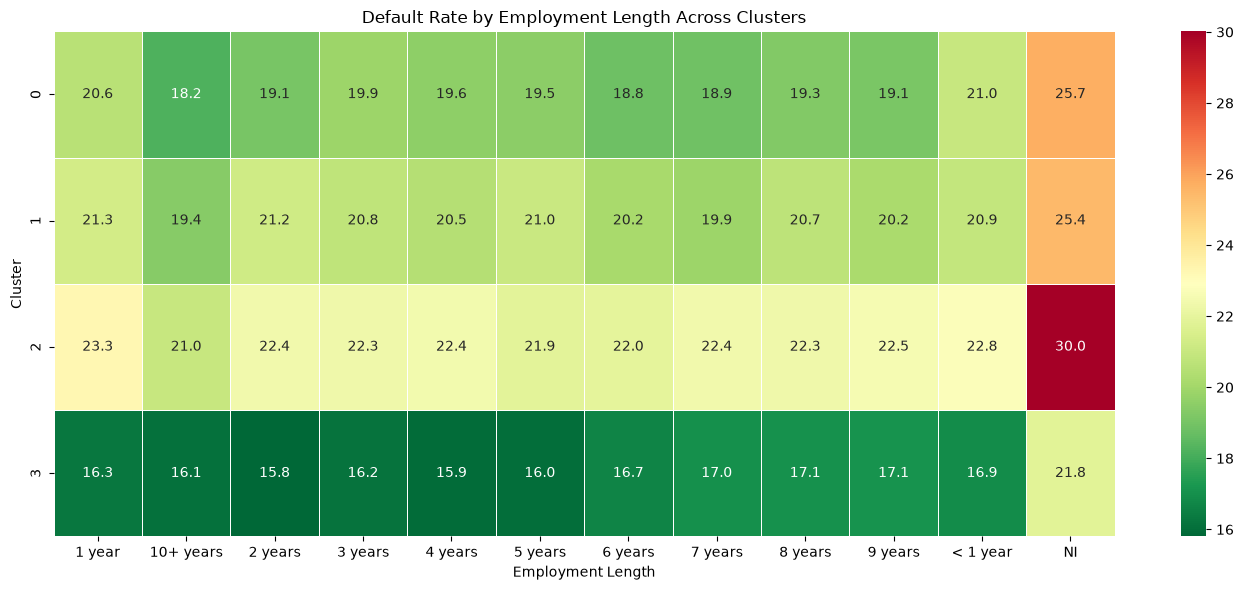

In [84]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    employment_risk,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    linewidths=0.5
)

plt.title("Default Rate by Employment Length Across Clusters")
plt.xlabel("Employment Length")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

Home ownership risk analysis

In [85]:
ownership_risk = df_clustered.pivot_table(
    index="Cluster",
    columns="home_ownership_n",
    values="Default",
    aggfunc="mean"
) * 100

ownership_counts = df_clustered.pivot_table(
    index="Cluster",
    columns="home_ownership_n",
    values="Default",
    aggfunc="count",
    fill_value=0
)

ownership_risk = ownership_risk.where(
    ownership_counts >= 100
)

display(ownership_risk.round(2))

home_ownership_n,MORTGAGE,OTHER,OWN,RENT
Cluster,,,,
0,16.82,NaN,20.47,23.88
1,17.99,NaN,21.54,26.44
2,18.99,17.61,22.15,25.38
3,14.64,20.54,16.91,18.13


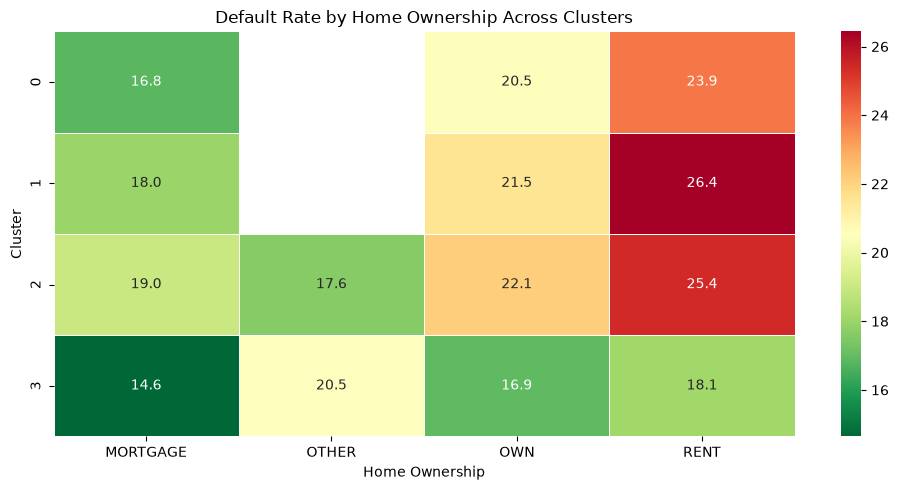

In [86]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    ownership_risk,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    linewidths=0.5
)

plt.title("Default Rate by Home Ownership Across Clusters")
plt.xlabel("Home Ownership")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

### Anomaly Detection

In [87]:
from sklearn.ensemble import IsolationForest

In [88]:
isolation_forest = IsolationForest(
    n_estimators=100,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

anomaly_labels = isolation_forest.fit_predict(X_sample)

print("Anomaly detection completed!")

print("\nResults:")
print(pd.Series(anomaly_labels).value_counts())

print(
    "\nAnomaly percentage:",
    round(np.mean(anomaly_labels == -1) * 100, 2),
    "%"
)

Anomaly detection completed!

Results:
 1    49500
-1      500
Name: count, dtype: int64

Anomaly percentage: 1.0 %


In [89]:
anomaly_df = df.iloc[sample_indices].copy()

anomaly_df["Anomaly_Status"] = np.where(
    anomaly_labels == -1,
    "Anomaly",
    "Normal"
)

anomaly_summary = anomaly_df.groupby(
    "Anomaly_Status"
).agg(
    Borrowers=("Default", "count"),
    Default_Count=("Default", "sum"),
    Default_Rate=("Default", "mean"),
    Average_Income=("revenue", "mean"),
    Average_FICO=("fico_n", "mean"),
    Average_Loan=("loan_amnt", "mean"),
    Average_DTI=("dti_n", "mean")
)

anomaly_summary["Default_Rate"] *= 100

display(anomaly_summary.round(3))

,Borrowers,Default_Count,Default_Rate,Average_Income,Average_FICO,Average_Loan,Average_DTI
Anomaly_Status,,,,,,,
Anomaly,500,96,19.200,89597.765,735.330,14971.000,13.100
Normal,49500,9877,19.954,77349.274,697.868,14413.088,18.289


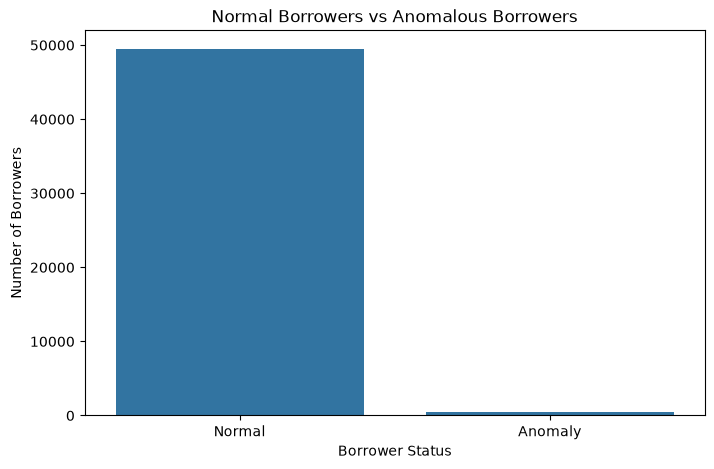

In [90]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=anomaly_df,
    x="Anomaly_Status"
)

plt.title("Normal Borrowers vs Anomalous Borrowers")
plt.xlabel("Borrower Status")
plt.ylabel("Number of Borrowers")

plt.show()

which clusters contain anomalies

In [91]:
anomaly_df["Cluster"] = labels_k4

cluster_anomaly = anomaly_df.pivot_table(
    index="Cluster",
    columns="Anomaly_Status",
    values="Default",
    aggfunc="count",
    fill_value=0
)

cluster_anomaly["Anomaly_Percentage"] = (
    cluster_anomaly["Anomaly"] /
    cluster_anomaly.sum(axis=1) * 100
)

display(cluster_anomaly.round(2))

Anomaly_Status,Anomaly,Normal,Anomaly_Percentage
Cluster,,,
0,136,16321,0.83
1,202,6207,3.15
2,65,15425,0.42
3,97,11547,0.83


In [92]:
anomaly_features = anomaly_df.groupby(
    "Anomaly_Status"
).agg(
    Average_Income=("revenue", "mean"),
    Average_FICO=("fico_n", "mean"),
    Average_Loan=("loan_amnt", "mean"),
    Average_DTI=("dti_n", "mean"),
    Average_Revenue=("revenue", "median")
)

display(anomaly_features.round(2))

,Average_Income,Average_FICO,Average_Loan,Average_DTI,Average_Revenue
Anomaly_Status,,,,,
Anomaly,89597.76,735.33,14971.00,13.10,65000.0
Normal,77349.27,697.87,14413.09,18.29,65000.0


In [93]:
anomaly_df["Anomaly_Score"] = (
    isolation_forest.decision_function(X_sample)
)

most_unusual = anomaly_df[
    anomaly_df["Anomaly_Status"] == "Anomaly"
].sort_values("Anomaly_Score").head(20)

display(
    most_unusual[
        [
            "revenue",
            "fico_n",
            "loan_amnt",
            "dti_n",
            "purpose",
            "Default",
            "Cluster",
            "Anomaly_Score"
        ]
    ]
)

,revenue,fico_n,loan_amnt,dti_n,purpose,Default,Cluster,Anomaly_Score
1262536,130000.0,787.0,40000,6.66,house,0,3,-0.076064
953815,4888.0,722.0,1400,17.68,vacation,0,0,-0.067076
1300629,200000.0,772.0,35000,0.97,small_business,1,3,-0.056097
951352,60000.0,722.0,16000,19.06,small_business,0,0,-0.052088
549906,145000.0,737.0,40000,12.48,house,0,3,-0.051943
1173258,14000.0,702.0,3000,3.43,moving,1,0,-0.048919
915465,250000.0,802.0,40000,4.27,major_purchase,0,3,-0.043524
955269,101300.0,662.0,18000,14.42,house,0,0,-0.042718
391354,98500.0,817.0,40000,10.31,home_improvement,0,1,-0.042653
646713,205000.0,797.0,35000,5.74,house,0,1,-0.041110


default rate within each cluster

In [94]:
anomaly_risk_by_cluster = anomaly_df.pivot_table(
    index="Cluster",
    columns="Anomaly_Status",
    values="Default",
    aggfunc=["count", "mean"]
)

display(anomaly_risk_by_cluster.round(4))

count           mean        
Anomaly_Status Anomaly Normal Anomaly  Normal
Cluster                                      
0                  136  16321  0.2647  0.2064
1                  202   6207  0.1089  0.0960
2                   65  15425  0.1538  0.2211
3                   97  11547  0.2887  0.2167

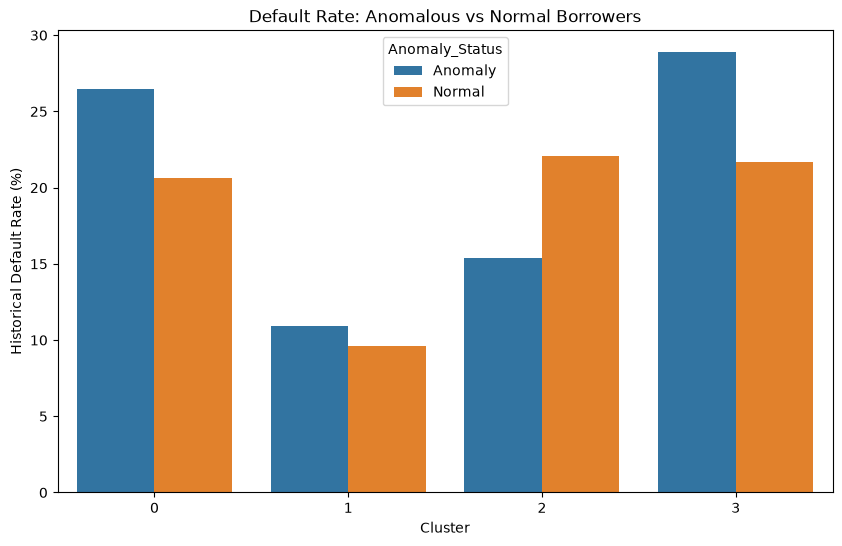

In [95]:
risk_plot = anomaly_df.groupby(
    ["Cluster", "Anomaly_Status"]
)["Default"].mean().reset_index()

risk_plot["Default"] *= 100

plt.figure(figsize=(10, 6))

sns.barplot(
    data=risk_plot,
    x="Cluster",
    y="Default",
    hue="Anomaly_Status"
)

plt.title("Default Rate: Anomalous vs Normal Borrowers")
plt.xlabel("Cluster")
plt.ylabel("Historical Default Rate (%)")

plt.show()

Isolation Forest identified 1% of the sampled borrowers as anomalous. The detected observations generally exhibited higher average income and FICO scores and lower DTI values than normal observations. Cluster-level analysis revealed varying default patterns, with anomalous borrowers showing higher historical default rates in Clusters 0 and 3, but a lower rate in Cluster 2. Therefore, anomaly detection identifies unusual borrower characteristics rather than directly identifying high-risk borrowers.

Verify model and preprocessing objects

In [96]:
print("Preprocessing objects:")
print("Encoder:", type(encoder))
print("Imputer:", type(imputer))
print("Scaler:", type(scaler))

print("\nClustering model:")
print(type(final_kmeans))

print("\nFeature information:")
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

print("\nFinal dataset shape:", df_clustered.shape)
print("Processed feature shape:", X_processed.shape)

Preprocessing objects:
Encoder: <class 'sklearn.preprocessing._encoders.OneHotEncoder'>
Imputer: <class 'sklearn.impute._base.SimpleImputer'>
Scaler: <class 'sklearn.preprocessing._data.StandardScaler'>

Clustering model:
<class 'sklearn.cluster._kmeans.MiniBatchKMeans'>

Feature information:
Numerical features: ['revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'issue_year', 'issue_month']
Categorical features: ['emp_length', 'purpose', 'home_ownership_n']

Final dataset shape: (1347681, 18)
Processed feature shape: (1347681, 37)


In [97]:
import joblib

model_artifacts = {
    "model": final_kmeans,
    "encoder": encoder,
    "imputer": imputer,
    "scaler": scaler,
    "numerical_features": numerical_features,
    "categorical_features": categorical_features,
    "cluster_profile": final_profile,
    "revenue_log_transform": True
}

joblib.dump(
    model_artifacts,
    "credit_portfolio_model.pkl"
)

print("Model artifacts saved successfully!")

Model artifacts saved successfully!


In [98]:
loaded_artifacts = joblib.load("credit_portfolio_model.pkl")

print("Model:", type(loaded_artifacts["model"]))
print("Encoder:", type(loaded_artifacts["encoder"]))
print("Imputer:", type(loaded_artifacts["imputer"]))
print("Scaler:", type(loaded_artifacts["scaler"]))

print("\nNumerical features:",
      loaded_artifacts["numerical_features"])

print("\nCategorical features:",
      loaded_artifacts["categorical_features"])

print("\nSaved model verified successfully!")

Model: <class 'sklearn.cluster._kmeans.MiniBatchKMeans'>
Encoder: <class 'sklearn.preprocessing._encoders.OneHotEncoder'>
Imputer: <class 'sklearn.impute._base.SimpleImputer'>
Scaler: <class 'sklearn.preprocessing._data.StandardScaler'>

Numerical features: ['revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'issue_year', 'issue_month']

Categorical features: ['emp_length', 'purpose', 'home_ownership_n']

Saved model verified successfully!
